### Hex coordinate stuff, leading to Koch snowflake

Based on https://www.redblobgames.com/grids/hexagons/

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product, count

In [2]:
# Centers of hexes make a triangluar grid.  Coordinates are q, r, s, where q+r+s=0 (so, redundant)
# Instantiate as numpy array to allow vector arithmetic

cube_dirs = np.array([(+1, 0, -1), (+1, -1, 0), (0, -1, +1), (-1, 0, +1), (-1, +1, 0), (0, +1, -1)])

def cube_ring(center, radius):
    results = []
    hex = center + radius*cube_dirs[4]
    for i in cube_dirs:
        for _ in range(radius):
            results.append(hex)
            hex = hex + i
    return np.array(results)

def cube_spiral(center, radius):
    results = [center]
    for i in range(1,radius+1):
        results.append(cube_ring(center, i))
    return np.vstack(results)
        
#qrs_xy = np.array([[1.5, 0, 0],[np.sqrt(3)/2, np.sqrt(3), 0]])

# Matrix to convert qrs coordinates to xy coordinates
qrs_xy = np.array([[np.sqrt(3), np.sqrt(3)/2, 0],[0, 1.5, 0]])

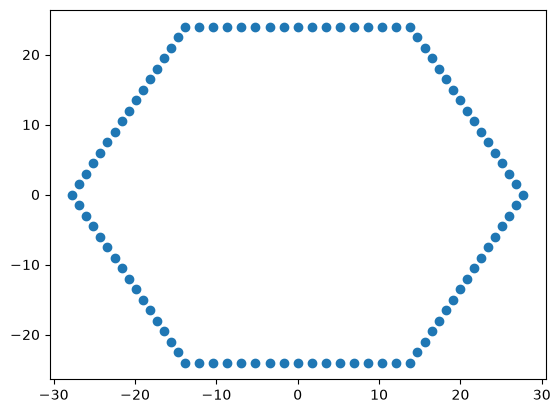

In [3]:
ring = qrs_xy @ cube_ring([0,0,0],16).T
plt.scatter(ring[0],ring[1])

In [4]:
def koch_side(depth, heading, start):
    if depth == 0:
        #print(depth, heading, cube_dirs[heading], start, '!')
        return start + cube_dirs[heading]
        return [start,start + cube_dirs[heading]]
    loc = start

    results = koch_side(depth-1, heading, loc)

    loc = loc + cube_dirs[heading] * 3**(depth-1)
    heading = (heading+5) % 6
    results= np.vstack((results, koch_side(depth-1, heading, loc)))

    loc = loc + cube_dirs[heading] * 3**(depth-1)
    heading = (heading+2) % 6
    results= np.vstack((results, koch_side(depth-1, heading, loc)))

    loc = loc + cube_dirs[heading] * 3**(depth-1)
    heading = (heading+5) % 6
    results= np.vstack((results, koch_side(depth-1, heading, loc)))

    #print(depth, heading, cube_dirs[heading], start, results, '!')
    return(results)

def koch_triangle(depth, start):
    loc = start
    heading = 0
    results = koch_side(depth, heading, loc)

    loc = loc + cube_dirs[heading] * 3**(depth)
    heading = (heading+2) % 6
    results= np.vstack((results, koch_side(depth, heading, loc)))

    loc = loc + cube_dirs[heading] * 3**(depth)
    heading = (heading+2) % 6
    results= np.vstack((results, koch_side(depth, heading, loc)))

    return results

In [5]:
def interior_trim(allpts, base):
    "From allpts, return a list of those reachable from base"
    frontier = [base]
    dapts = set(allpts)
    reached = set()
    while frontier:
        newpt = frontier.pop()
        reached.add(tuple(newpt))
        for nbr in newpt + cube_dirs:
            if tuple(nbr) in dapts and tuple(nbr) not in reached:
                #print(nbr, tuple(newpt))
                frontier.append(nbr)
    return [x for x in allpts if x in reached]

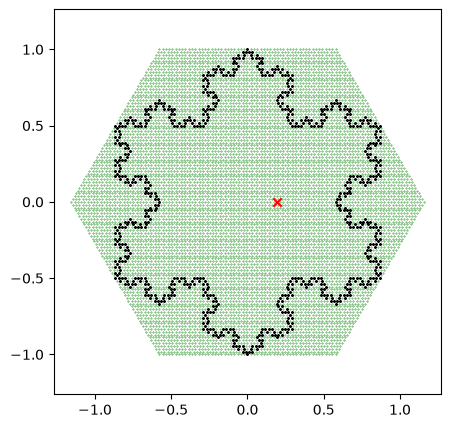

In [6]:
N = 4
#koch3 = qrs_xy @ koch_side(5, 0, [0,0,0]).T
#ring = qrs_xy @ cube_ring([0,0,0],54).T

hexes = cube_spiral([0,0,0], 2*3**(N-1))
kochy = koch_triangle(N, 3**(N-1)*(cube_dirs[4]+cube_dirs[3]))

#ring = qrs_xy @ cube_spiral([0,0,0], 2*3**(N-1)).T
#koch = qrs_xy @ koch_triangle(N, 3**(N-1)*(cube_dirs[4]+cube_dirs[3])).T
ring = qrs_xy @ hexes.T / (3 ** (N))
koch = qrs_xy @ kochy.T / (3 ** (N))
plt.gcf().set_size_inches(5,5)
plt.gca().axis('equal')
plt.scatter(ring[0],ring[1], s=0.1, color='green')
plt.scatter(koch[0], koch[1], marker='*', color='black', s=1.5)

basex = 3**(N-2)
basept = qrs_xy @ [basex,0,-basex] / (3 ** N)
plt.scatter(basept[0],basept[1],marker='x', color='red')
boundary = [tuple(x) for x in kochy]
#interior = [x for x in map(tuple, hexes) if x not in boundary]
interior = interior_trim([x for x in map(tuple,hexes) if x not in boundary], [0,0,0])

#plt.savefig('koch4.pdf')
#intpt = qrs_xy @ np.array(interior).T
#plt.scatter(intpt[0], intpt[1])

In [7]:
len(interior)

4789

In [8]:
def buildmatrix(boundary, interior):
    """from list of boundary coordinates and interior coordinates, build the transistion matrix,
    assuming boundary points are absorbing.  Follows the procedure in Snell and Doyle.
    The return matrix B contains the exit distribution starting at any interior point."""
    u = len(boundary)
    v = len(interior)
    R = np.zeros((v, u))
    Q = np.zeros((v, v))
    intidx = dict(zip(interior, count()))
    bdyidx = dict(zip(boundary, count()))
    for (q,r,s) in interior:
        #print(x,y)
        inbrs = []
        bnbrs = []
        for (nq,nr,ns) in [q,r,s]+cube_dirs:
            if (nq, nr, ns) in bdyidx:
                bnbrs.append(bdyidx[(nq, nr, ns)])
            if (nq, nr, ns) in intidx:
                inbrs.append(intidx[(nq, nr, ns)])
        tnbrs = len(inbrs) + len(bnbrs)
        for nidx in bnbrs:
            R[intidx[(q,r,s)], nidx] += 1/tnbrs
        for nidx in inbrs:
            Q[intidx[(q,r,s)], nidx] += 1/tnbrs
    #B = np.matmul(np.linalg.inv(np.eye(v)-Q), R) # as in Snell and Doyle, but...
    B = np.linalg.solve(np.eye(v)-Q, R)           # this is better
    return B

In [9]:
%%time 
B = buildmatrix(boundary, interior)

CPU times: user 3.85 s, sys: 260 ms, total: 4.11 s
Wall time: 1.53 s


In [10]:
intidx = dict(zip(interior, count()))
bdyidx = dict(zip(boundary, count()))

R = 2 * 3 ** (N-1)

basex = 3**(N-2)
#basex = 0
basept = (basex,0,-basex)
baseidx = intidx[basept]

refptxy = qrs_xy @ [basex, 0, -basex]
boundaryxy = qrs_xy @ np.array(boundary).T
bx = boundaryxy[0]
by = boundaryxy[1]
dists = np.sqrt((bx - refptxy[0]) ** 2 + (by - refptxy[1])**2)

r = np.linspace(0,2*R,400)
harm = r*0
for i in range(len(r)):
    harm[i] = np.dot(B[baseidx], dists < r[i])

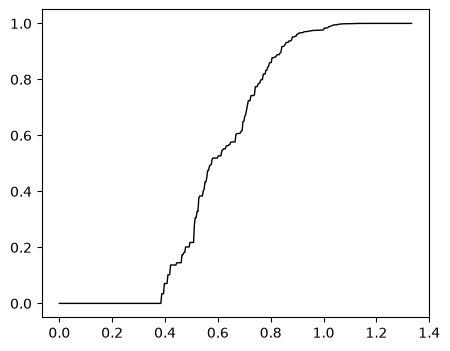

In [11]:
plt.gcf().set_size_inches(5,4)
#plt.title('$h$ function, Koch snowflake, depth 5')
#plt.plot(r,harm, color='black', lw=0.8, label=f"depth 4")
plt.plot(r/(3**N),harm, color='black', lw=1.0, label=f"(1/9, 0)")
#plt.scatter(pharm4[:,0], pharm4[:,1], color='red', s=0.1)
#plt.legend(loc='lower right')
#plt.savefig('kochharm4_1_9.pdf')

In [12]:
# Instead of evenly spaced points, plot one point for each boundary point, ordered by distance from basept

pharm = list(zip(dists,B[baseidx]))
pharm.sort()
total = 0
xformed = []
for a,b in pharm:
    total += b
    xformed.append((a,total))

pharm = np.array(xformed).T

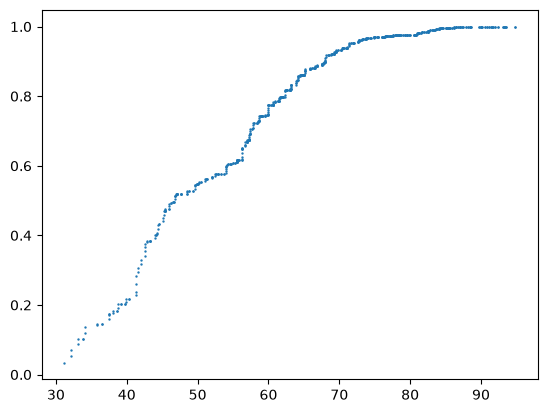

In [14]:
plt.scatter(pharm[0],pharm[1],s=0.5)

In [14]:
def koch_h(N=4):
    "Compute the exit distribution for Koch snowflake of depth N, starting at (1/5, 0)"
    hexes = cube_spiral([0,0,0], 2*3**(N-1))
    kochy = koch_triangle(N, 3**(N-1)*(cube_dirs[4]+cube_dirs[3]))
    
    ring = qrs_xy @ hexes.T / (3 ** (N))
    koch = qrs_xy @ kochy.T / (3 ** (N))
    plt.gcf().set_size_inches(5,5)
    plt.gca().axis('equal')
    plt.scatter(ring[0],ring[1], s=0.1, color='green')
    plt.scatter(koch[0], koch[1], marker='*', color='black', s=1.5)
    
    basex = 3**(N-2)
    basept = qrs_xy @ [basex,0,-basex] / (3 ** N)
    plt.scatter(basept[0],basept[1],marker='x', color='red')
    boundary = [tuple(x) for x in kochy]
    # maybe should plot only these points instead of ring above?
    interior = interior_trim([x for x in map(tuple,hexes) if x not in boundary], [0,0,0])
    #plt.savefig(f'koch{N}.pdf')
    #intpt = qrs_xy @ np.array(interior).T
    #plt.scatter(intpt[0], intpt[1])

    # already quite slow at N=5
    B = buildmatrix(boundary, interior)

    intidx = dict(zip(interior, count()))
    bdyidx = dict(zip(boundary, count()))
    
    R = 2 * 3 ** (N-1)
    
    basept = (basex,0,-basex) # qrs coordinates
    baseidx = intidx[basept]
    
    refptxy = qrs_xy @ [basex, 0, -basex]
    boundaryxy = qrs_xy @ np.array(boundary).T
    bx = boundaryxy[0]
    by = boundaryxy[1]
    dists = np.sqrt((bx - refptxy[0]) ** 2 + (by - refptxy[1])**2)
    
    r = np.linspace(0,2*R,400)
    harm = r*0
    for i in range(len(r)):
        harm[i] = np.dot(B[baseidx], dists < r[i])
    return harm

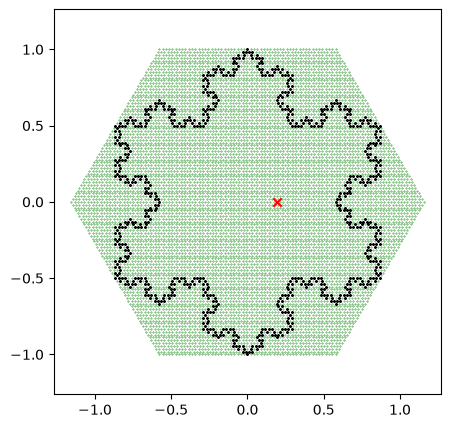

In [15]:
harm4 = koch_h(4)

CPU times: user 52min 51s, sys: 56.7 s, total: 53min 47s
Wall time: 11min 20s


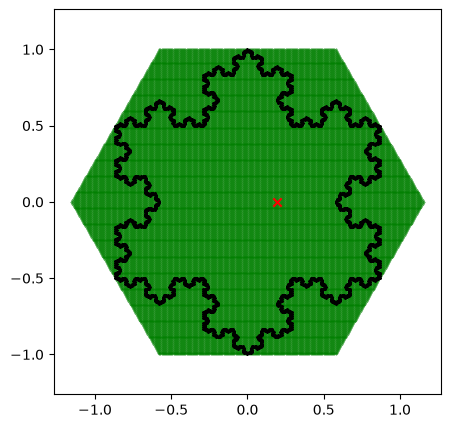

In [16]:
%%time
harm5 = koch_h(5)

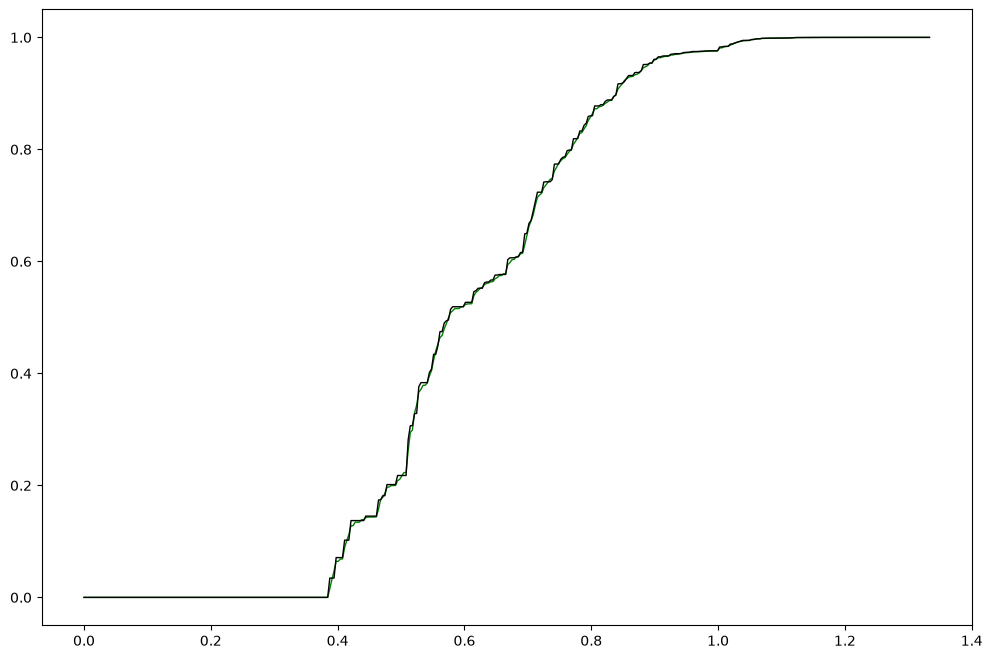

In [17]:
r = np.linspace(0,4/3,400)

plt.gcf().set_size_inches(12,8)
#plt.title('$h$ function, Koch snowflake, depth 5')
#plt.plot(r,harm, color='black', lw=0.8, label=f"depth 4")
plt.plot(r,harm5, color='green', lw=1.0, label=f"(1/9, 0)")
plt.plot(r,harm4, color='black', lw=1.0, label=f"(1/9, 0)")
#plt.savefig('kochharm45.pdf')